In [7]:
from IPython.display import display, HTML

display(HTML("""
<style>

.jp-RenderedMarkdown {
    font-family: "Segoe UI", Roboto, sans-serif;
    line-height: 1.6;
}

.jp-RenderedMarkdown h1 {
    text-align: center;
    border-bottom: 3px solid #222;
    padding-bottom: 0.4em;
    margin-top: 0.5em;
}

.jp-RenderedMarkdown h2 {
    border-left: 6px solid #444;
    padding-left: 0.6em;
    margin-top: 1.8em;
}

.jp-RenderedMarkdown h3 {
    margin-top: 1.2em;
    font-weight: 600;
}

table {
    border-collapse: collapse;
}

th, td {
    border: 1px solid #aaa;
    padding: 6px 10px;
}

</style>
"""))

# Raport Laboratori – Elektronikë

**Titulli i Eksperimentit:** Analiza e Qarqeve Rezistive dhe Përdorimi i Breadboard-it  
**Lënda:** Hyrje në Elektronikë (Viti III, Fizikë dhe Shkenca Kompjuterike)  
**Pedagogu:** Ervin Kafexhiu dhe Gerti Xhixha  
**Studenti:** Arlind Laçka    
**Data e zhvillimit:** 17.11.2026  
**Data e dorëzimit:** 18.11.2026  

---

## 1. Qëllimi i Eksperimentit

Në këtë eksperiment u studiua sjellja e qarqeve elektrike DC duke përdorur pllakën e montimit (*breadboard*). Qëllimi kryesor ishte verifikimi eksperimental i Ligjit të Ohmit për rezistenca të ndryshme. Gjithashtu u analizua rënia e tensionit dhe shpërndarja e rrymës në konfigurime serike dhe paralele. U krahasuan vlerat e matura me instrumente laboratorike me ato teorike të llogaritura.

---

## 2. Baza Teorike

### 2.1 Modeli i Qarkut
Për realizimin e matjeve u përdorën:
- Vlerat nominale të rezistencave: $R_1 = 120\text{ k}\Omega$ dhe $R_2 = 1.77\text{ k}\Omega$
- Tensioni i burimit të ushqimit DC: $V_{\text{in}} = 11.69\text{ V}$
- Pajisjet matëse: Multimetri dixhital dhe furnizuesi i energjisë.

### 2.2 Ekuacionet Themelore
Lidhja midis tensionit, rrymës dhe rezistencës jepet nga Ligji i Ohmit:
$$I = \frac{V}{R}$$

---

## 3. Ndërtimi Eksperimental

### 3.1 Pajisjet
| Pajisja | Modeli | Diapazoni | Saktësia |
| :--- | :--- | :--- | :--- |
| Multimetër | Dixhital Standard | Auto / Manual | ±(0.5% + 2 digits) |
| Furnizues funksionesh / DC | Regolueshëm | 0 - 30 V | ±1% |
| Breadboard | Standard 830 pika | - | - |

---

## 4. Të Dhënat e Matura

In [8]:
import os
import pandas as pd

# Sigurohemi që folderi data ekziston brenda LAB01
os.makedirs('data', exist_ok=True)

# Krijimi i të dhënave të matura eksperimentale
data = pd.DataFrame({
    "Konfigurimi": ["Burimi direkt", "Lidhje në Seri", "Lidhje në Paralel"],
    "Rezistenca": ["120 kΩ dhe 1.77 kΩ", "120 kΩ dhe 1.77 kΩ", "120 kΩ dhe 1.77 kΩ"],
    "Rryma (A)": [2.263, 0.000, 2.256],
    "Vin (V)": [11.69, 11.69, 11.69],
    "Vout (V)": ["N/A", 3.93, 11.36]
})

# Llogaritja e raportit të amplifikimit/tensionit
data["Amplifikimi"] = pd.to_numeric(data["Vout (V)"], errors='coerce') / data["Vin (V)"]

# Ruajtja e të dhënave në formatin CSV te folderi data/
data.to_csv('data/tabela_matjet.csv', index=False)

# Shfaqja e tabelës
data

,Konfigurimi,Rezistenca,Rryma (A),Vin (V),Vout (V),Amplifikimi
0,Burimi direkt,120 kΩ dhe 1.77 kΩ,2.263,11.69,N/A,NaN
1,Lidhje në Seri,120 kΩ dhe 1.77 kΩ,0.000,11.69,3.93,0.336185
2,Lidhje në Paralel,120 kΩ dhe 1.77 kΩ,2.256,11.69,11.36,0.971771


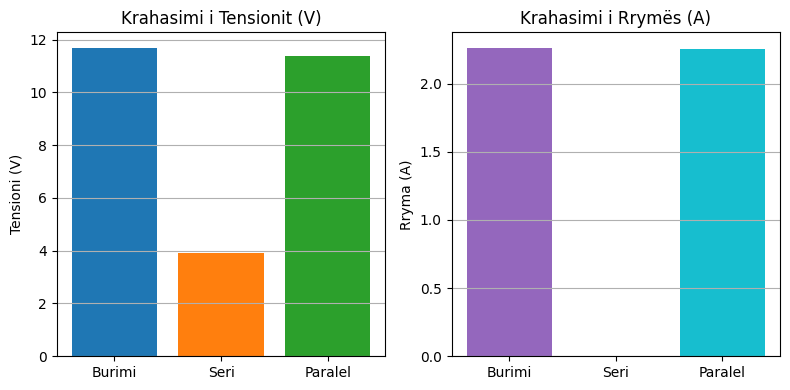

In [9]:
import os
import matplotlib.pyplot as plt
import numpy as np

# Sigurohemi që folderi figs ekziston brenda LAB01
os.makedirs('figs', exist_ok=True)

konfigurimet = ['Burimi', 'Seri', 'Paralel']
tensionet = [11.69, 3.93, 11.36]
rrymat = [2.263, 0.0, 2.256]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.bar(konfigurimet, tensionet, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
ax1.set_title("Krahasimi i Tensionit (V)")
ax1.set_ylabel("Tensioni (V)")
ax1.grid(True, axis='y')

ax2.bar(konfigurimet, rrymat, color=['#9467bd', '#d62728', '#17becf'])
ax2.set_title("Krahasimi i Rrymës (A)")
ax2.set_ylabel("Rryma (A)")
ax2.grid(True, axis='y')

plt.tight_layout()
# Ruajtja e figurës në folderin figs/
plt.savefig('figs/grafiku_matjet.png', dpi=300, bbox_inches='tight')
plt.show()